# Entrega E1 · Tema 3. GLM para clasificación

**Técnicas Avanzadas de Predicción en Negocios · Entrega evaluable · 22-10-2026**

Datos: Encuesta Cuatrienal de Estructura Salarial 2022 (INE), microdatos. Cada alumno trabaja con una muestra propia de 10 000 trabajadores.

**Cómo está organizada la entrega**

- **Parte A. Código mostrado.** Ejecuta y lee cada celda. Es el patrón que usarás en la parte B.
- **Parte B. Actividad.** Tres bloques con tareas cortas de código que escribes tú, de principio a fin, y una interpretación al final de cada bloque.
- **Cierre.** Una celda guarda tus respuestas en un fichero `.json`. Subes el cuaderno y ese fichero.

Tienes **120 minutos**, incluidos la revisión y la subida. Orientación: 10 min para la preparación, 20 para la parte A, 20 para cada bloque de la parte B y 15 para el cierre.

## 0. Tu usuario

> **Escribe solo tu nombre de usuario de la UV**, el de tu cuenta de Aula Virtual, sin `@alumni.uv.es`.
> **No escribas tu nombre, DNI, NIU ni correo.** El cuaderno no debe contener ningún dato personal.

El usuario se convierte en un número entero, tu **semilla**. La semilla fija tu muestra de datos y tus particiones, así que cada alumno obtiene resultados distintos.

In [1]:
import zlib

# Escribe tu usuario UV entre las comillas.
USUARIO = "prueba01"

# Normalizamos el texto y lo convertimos en un entero: tu semilla.
USUARIO = USUARIO.strip().lower().split("@")[0].replace(" ", "")
assert USUARIO != "escribe_aqui_tu_usuario", "Escribe tu usuario UV entre las comillas."
SEMILLA = zlib.crc32(USUARIO.encode()) % 10**6
print("Usuario:", USUARIO, "| semilla:", SEMILLA)

Usuario: prueba01 | semilla: 698722


### Preparación

**Ejecuta la celda siguiente.** Carga las bibliotecas y los datos y conserva la población del tema 2 (salario positivo, con tope en el percentil 99). Después elige 10 000 trabajadores con tu semilla. No hace falta leerla. Tarda unos segundos porque descarga los datos.

In [2]:
# Bibliotecas para tratar datos y dibujar.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# Preparación de los predictores y modelos.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Divisiones, validación cruzada y búsqueda de hiperparámetros.
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict

# Métricas y matriz de confusión.
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    recall_score, precision_score, log_loss,
)

plt.rcParams.update({"figure.figsize": (5, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

# Datos de la EES 2022 en la web del curso (separador: tabulación).
URL_DATOS = "https://juandmontoro.github.io/tap/data/EES_2022.tab"
df = pd.read_csv(URL_DATOS, sep="\t", low_memory=False)
df.columns = df.columns.str.replace('"', "").str.strip()

# Población del tema 2: salario positivo y hasta el percentil 99.
tope = df["RETRINOIN"].quantile(0.99)
salario_admitido = (df["RETRINOIN"] > 0) & (df["RETRINOIN"] <= tope)
limpio = df[salario_admitido].copy()

# Tu muestra: 10 000 trabajadores elegidos con tu semilla.
datos = limpio.sample(n=10000, random_state=SEMILLA).reset_index(drop=True)
print("Observaciones:", len(datos))
print("Versión de scikit-learn:", sklearn.__version__)

Observaciones: 10000
Versión de scikit-learn: 1.9.1


### Predictores y división entre entrenamiento y test

Usamos los predictores del tema 2: 14 categóricos y 2 numéricos. El salario bruto anual (`RETRINOIN`) **no** es predictor, porque con él se definen las dos respuestas de esta entrega. Reservamos el 25 % de las observaciones para el test, que en esta entrega no se usa.

In [3]:
PRED_CATEGORICOS = [
    "SEXO", "ESTU", "ANOS2", "TIPOCON", "TIPOJOR", "CNO1", "CNACE",
    "CONTROL", "MERCADO", "REGULACION", "RESPONSA", "NUTS1", "TIPOPAIS", "ESTRATO2",
]
PRED_NUMERICOS = ["ANOANTI", "JAP"]

# X contiene los predictores e y, el salario.
X = datos[PRED_CATEGORICOS + PRED_NUMERICOS].copy()
X[PRED_CATEGORICOS] = X[PRED_CATEGORICOS].astype("category")
y = datos["RETRINOIN"]

# Separamos el test antes de ajustar ningún modelo.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEMILLA)
print("Entrenamiento:", len(X_train), "| test:", len(X_test))

Entrenamiento: 7500 | test: 2500


El preprocesador es el del tema 2: escala las variables numéricas y crea columnas indicadoras para las categóricas. Cada llamada a `crear_preprocesador()` devuelve uno nuevo, sin ajustar.

In [4]:
# Devuelve un preprocesador nuevo en cada llamada.
def crear_preprocesador():
    return ColumnTransformer([
        ("numericas", StandardScaler(), PRED_NUMERICOS),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01,
                                      sparse_output=False), PRED_CATEGORICOS),
    ])

# Parte A. Código mostrado

Ejecuta y lee cada celda. En esta parte no hay preguntas: es el patrón que adaptarás en la parte B.

## A1. Logit binario: ¿salario alto?

La respuesta vale 1 si el salario supera el **percentil 75 del entrenamiento** y 0 en otro caso, así que un 25 % de los trabajadores son «altos». El logit es un GLM con respuesta binaria y enlace logit: estima la probabilidad de ser alto.

Obtenemos la probabilidad de validación cruzada de cada trabajador con `cross_val_predict`, como en el tema 2. `StratifiedKFold` mantiene en cada partición la proporción de altos.

> **Python que usamos aquí**
> - `cross_val_predict(..., method="predict_proba")` devuelve una columna por clase. `[:, 1]` se queda con la columna de la clase 1 (alto).
> - `(prob_alto_cv >= 0.5).astype(int)` vale 1 donde la probabilidad llega al umbral y 0 donde no.

In [5]:
# Umbral del salario alto: percentil 75 del entrenamiento.
p75 = y_train.quantile(0.75)

# Respuesta binaria: 1 = salario alto, 0 = no.
alto_train = (y_train > p75).astype(int)
print("P75:", round(p75), "euros | proporción de altos:", round(alto_train.mean(), 3))

# Cinco particiones que conservan la proporción de cada clase.
cv_estratificada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Modelo completo: preprocesador seguido del logit.
logit = Pipeline([
    ("preprocesado", crear_preprocesador()),
    ("modelo", LogisticRegression(max_iter=2000)),
])

# Probabilidad de validación cruzada de ser alto (columna de la clase 1).
prob_alto_cv = cross_val_predict(logit, X_train, alto_train, cv=cv_estratificada,
                                 method="predict_proba")[:, 1]

P75: 35225 euros | proporción de altos: 0.25


Con el umbral 0,5 obtenemos la clase predicha, la matriz de confusión y las métricas del tema 2. La log-loss mide la calidad de las probabilidades: cuanto menor, mejor. Su referencia es un modelo que asigna a todos la misma probabilidad, la proporción de altos.

> **Python que usamos aquí**
> - `confusion_matrix(observado, predicho)` devuelve una tabla: filas = clase observada (0, 1), columnas = clase predicha (0, 1).
> - `matriz_05[0, 1]` es la casilla de la fila 0 y la columna 1: observados 0 que el modelo predice como 1, es decir, los **falsos positivos**.
> - `np.full(n, valor)` crea un vector de longitud `n` con el mismo valor repetido.

In [6]:
# Clase predicha con el umbral 0,5.
pred_05 = (prob_alto_cv >= 0.5).astype(int)

# Matriz de confusión: filas = observado, columnas = predicho.
matriz_05 = confusion_matrix(alto_train, pred_05)
print(matriz_05)
print("Falsos positivos:", matriz_05[0, 1])

# Sensibilidad, precisión y log-loss.
sens_05 = recall_score(alto_train, pred_05)
prec_05 = precision_score(alto_train, pred_05)
logloss_05 = log_loss(alto_train, prob_alto_cv)

# Referencia: la misma probabilidad (la proporción de altos) para todos.
prob_referencia = np.full(len(alto_train), alto_train.mean())
logloss_ref = log_loss(alto_train, prob_referencia)

print("Sensibilidad:", round(sens_05, 3), "| precisión:", round(prec_05, 3))
print("Log-loss:", round(logloss_05, 3), "| referencia:", round(logloss_ref, 3))

[[5225  400]
 [ 687 1188]]
Falsos positivos: 400
Sensibilidad: 0.634 | precisión: 0.748
Log-loss: 0.323 | referencia: 0.562


## A2. Logit multinomial: tres tramos salariales

Los tramos se definen con los **terciles del entrenamiento**: 0 = bajo, 1 = medio, 2 = alto, con un tercio de los trabajadores en cada uno. Con tres clases, `LogisticRegression` ajusta el **logit multinomial** sin cambiar ningún argumento: estima una probabilidad por tramo, y las tres suman 1. La clase predicha es la de mayor probabilidad.

> **Python que usamos aquí**
> - `pd.cut(y_train, bins=limites, labels=False)` asigna a cada salario el código del intervalo en que cae: 0, 1 o 2.
> - `prob_tramos_cv.argmax(axis=1)` devuelve, en cada fila, la posición de la columna con la mayor probabilidad: el tramo predicho.

In [7]:
# Límites de los tramos: terciles del salario en el entrenamiento.
limites = [-np.inf, y_train.quantile(1 / 3), y_train.quantile(2 / 3), np.inf]

# Tramo de cada trabajador: 0 = bajo, 1 = medio, 2 = alto.
tramo_train = pd.cut(y_train, bins=limites, labels=False)
NOMBRES_TRAMOS = ["bajo", "medio", "alto"]

# Con tres clases, LogisticRegression ajusta el logit multinomial.
multinomial = Pipeline([
    ("preprocesado", crear_preprocesador()),
    ("modelo", LogisticRegression(max_iter=2000)),
])

# Probabilidades de validación cruzada: una columna por tramo (0, 1, 2).
prob_tramos_cv = cross_val_predict(multinomial, X_train, tramo_train, cv=cv_estratificada,
                                   method="predict_proba")

# Tramo predicho: la columna con la mayor probabilidad.
tramo_predicho = prob_tramos_cv.argmax(axis=1)

En la matriz 3×3, las filas son los tramos observados y las columnas, los predichos. La diagonal recoge los aciertos. Con tres tramos del mismo tamaño, un clasificador que asigna siempre el mismo tramo acierta un tercio de las veces.

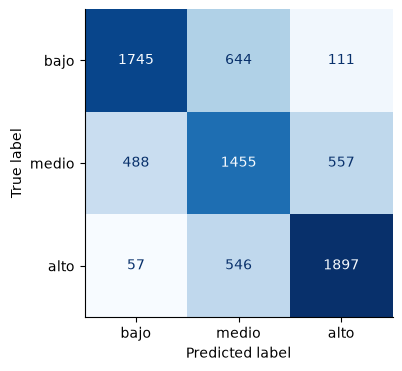

Exactitud: 0.68 | referencia: 0.333


In [8]:
# Matriz de confusión 3×3: filas = tramo observado, columnas = tramo predicho.
matriz_tramos = confusion_matrix(tramo_train, tramo_predicho)
ConfusionMatrixDisplay(matriz_tramos, display_labels=NOMBRES_TRAMOS).plot(cmap="Blues", colorbar=False)
plt.show()

# Exactitud frente a la referencia de un tercio.
exactitud = accuracy_score(tramo_train, tramo_predicho)
print("Exactitud:", round(exactitud, 3), "| referencia:", round(1 / 3, 3))

## A3. Penalización del multinomial con pocas observaciones

`LogisticRegression` penaliza la suma de los coeficientes al cuadrado, como Ridge. Su argumento `C` es el **inverso** de la intensidad de la penalización: un `C` pequeño penaliza mucho y un `C` grande casi nada. Con pocas observaciones, la penalización evita probabilidades extremas que fallan en validación.

Tomamos 300 observaciones del entrenamiento y buscamos `C` con `GridSearchCV`, con la log-loss como métrica.

> **Python que usamos aquí**
> - `tramo_train.loc[X_300.index]` toma las respuestas de las filas de la submuestra.
> - `GridSearchCV` usa la métrica con el signo cambiado (`neg_log_loss`): mayor es mejor. Por eso cambiamos el signo para leer la log-loss.
> - `cv_results_["mean_test_score"]` tiene un valor por `C`, en el orden de la malla. `[-1]` toma el último: el del `C` mayor.

In [9]:
# Submuestra de 300 observaciones del entrenamiento y sus tramos.
X_300 = X_train.sample(n=300, random_state=SEMILLA)
tramo_300 = tramo_train.loc[X_300.index]

# Malla de C entre 10**(-3) y 10**2.
MALLA_C = {"modelo__C": np.logspace(-3, 2, 11)}

# Cada C se evalúa con las mismas cinco particiones; métrica: log-loss.
busqueda_tramos = GridSearchCV(multinomial, MALLA_C, scoring="neg_log_loss", cv=cv_estratificada)
busqueda_tramos.fit(X_300, tramo_300)

# Log-loss media de validación de cada C (cambiamos el signo).
logloss_por_C = -busqueda_tramos.cv_results_["mean_test_score"]
print("C elegido:", busqueda_tramos.best_params_["modelo__C"])
print("Log-loss con ese C:", round(-busqueda_tramos.best_score_, 3),
      "| con el C mayor:", round(logloss_por_C[-1], 3))
pd.Series(logloss_por_C, index=MALLA_C["modelo__C"].round(4), name="Log-loss CV").round(3)

C elegido: 0.1
Log-loss con ese C: 0.81 | con el C mayor: 2.936


0.0010      1.062
0.0032      1.009
0.0100      0.930
0.0316      0.855
0.1000      0.810
0.3162      0.815
1.0000      0.887
3.1623      1.058
10.0000     1.382
31.6228     1.947
100.0000    2.936
Name: Log-loss CV, dtype: float64

# Parte B. Actividad

Cada bloque plantea un problema dividido en tareas cortas (T). En cada tarea:

- escribe el código completo en la celda «Escribe aquí tu solución»;
- crea los objetos **con los nombres exactos** que indica el enunciado: la corrección los busca por su nombre;
- adapta el código de la sección de la parte A que se indica.

Si una tarea no te sale, sigue con la siguiente: cada tarea se puntúa por separado.

Las interpretaciones se escriben entre las comillas triples `"""` de su celda. Responde a lo que se pregunta, **con tus cifras**.

## Bloque 1. Otro umbral para el logit binario

Solo un 25 % de los trabajadores son altos, y con el umbral 0,5 el modelo deja sin detectar a muchos de ellos. Probamos un umbral más bajo: la proporción de altos.

**T1.1.** Crea `umbral_b1`, la proporción de altos en `alto_train`, y `pred_b1`, la clase predicha con ese umbral a partir de `prob_alto_cv` (como `pred_05` en A1).

In [10]:
# T1.1 · umbral_b1 y pred_b1
umbral_b1 = alto_train.mean()
pred_b1 = (prob_alto_cv >= umbral_b1).astype(int)
print("Umbral:", round(umbral_b1, 3))

Umbral: 0.25


**T1.2.** Calcula la sensibilidad `sens_b1` y la precisión `prec_b1` con `pred_b1` (como en A1).

In [11]:
# T1.2 · sens_b1 y prec_b1
sens_b1 = recall_score(alto_train, pred_b1)
prec_b1 = precision_score(alto_train, pred_b1)
print("Sensibilidad:", round(sens_b1, 3), "| precisión:", round(prec_b1, 3))

Sensibilidad: 0.831 | precisión: 0.599


**T1.3.** Crea la matriz de confusión `matriz_b1` con `pred_b1` y guarda en `fp_b1` el número de falsos positivos (como en A1).

In [12]:
# T1.3 · matriz_b1 y fp_b1
matriz_b1 = confusion_matrix(alto_train, pred_b1)
fp_b1 = matriz_b1[0, 1]
print(matriz_b1)
print("Falsos positivos:", fp_b1)

[[4581 1044]
 [ 316 1559]]
Falsos positivos: 1044


**Interpretación 1.** Compara `matriz_b1` con `matriz_05` (A1).

1. Al bajar el umbral de 0,5 a `umbral_b1`, ¿qué casillas de la matriz aumentan y cuáles disminuyen? Da las cifras.
2. Explica con esas casillas por qué sube la sensibilidad y baja la precisión.
3. Si no detectar a un trabajador de salario alto cuesta más que una falsa alarma, ¿cuál de los dos umbrales elegirías? Justifícalo.

In [13]:
interp_b1 = f"""
1. Los verdaderos positivos pasan de {matriz_05[1, 1]} a {matriz_b1[1, 1]} y los falsos positivos de
{matriz_05[0, 1]} a {matriz_b1[0, 1]}; bajan los falsos negativos ({matriz_05[1, 0]} a {matriz_b1[1, 0]}) y
los verdaderos negativos ({matriz_05[0, 0]} a {matriz_b1[0, 0]}). Con un umbral menor, más trabajadores
se predicen como altos.
2. La sensibilidad (VP / altos observados) sube de {sens_05:.3f} a {sens_b1:.3f} porque aumentan los VP con
los mismos altos observados. La precisión (VP / predichos altos) baja de {prec_05:.3f} a {prec_b1:.3f} porque
los FP crecen más que los VP.
3. El umbral {umbral_b1:.2f}: si un falso negativo cuesta más que un falso positivo, conviene cambiar
falsos negativos por falsos positivos, que es lo que hace el umbral bajo.
"""
print(interp_b1)


1. Los verdaderos positivos pasan de 1188 a 1559 y los falsos positivos de
400 a 1044; bajan los falsos negativos (687 a 316) y
los verdaderos negativos (5225 a 4581). Con un umbral menor, más trabajadores
se predicen como altos.
2. La sensibilidad (VP / altos observados) sube de 0.634 a 0.831 porque aumentan los VP con
los mismos altos observados. La precisión (VP / predichos altos) baja de 0.748 a 0.599 porque
los FP crecen más que los VP.
3. El umbral 0.25: si un falso negativo cuesta más que un falso positivo, conviene cambiar
falsos negativos por falsos positivos, que es lo que hace el umbral bajo.



## Bloque 2. ¿Qué tal predice el multinomial?

Evaluamos con más detalle el logit multinomial de A2.

**T2.1.** Calcula `sens_tramos_b2`, la sensibilidad de cada tramo, con `recall_score` sobre `tramo_train` y `tramo_predicho`. Con tres clases, añade el argumento `average=None`: así devuelve una sensibilidad por tramo, en el orden 0, 1, 2.

In [14]:
# T2.1 · sens_tramos_b2
sens_tramos_b2 = recall_score(tramo_train, tramo_predicho, average=None)
print(pd.Series(sens_tramos_b2, index=NOMBRES_TRAMOS).round(3))

bajo     0.698
medio    0.582
alto     0.759
dtype: float64


**T2.2.** Un error **extremo** confunde el tramo bajo con el alto. Guarda en `errores_extremos_b2` la suma de los trabajadores de tramo bajo predichos como alto y los de tramo alto predichos como bajo. Léelos de `matriz_tramos` (A2) con índices `[fila, columna]`, como `matriz_05[0, 1]` en A1.

In [15]:
# T2.2 · errores_extremos_b2
errores_extremos_b2 = matriz_tramos[0, 2] + matriz_tramos[2, 0]
print("Errores extremos:", errores_extremos_b2)

Errores extremos: 168


**T2.3.** Calcula la log-loss del multinomial, `logloss_b2`, con `prob_tramos_cv`. Calcula también la de la referencia, `logloss_ref_b2`: un modelo que asigna probabilidad 1/3 a cada tramo. Constrúyela como la referencia de A1, pero con tres columnas: `np.full((n, 3), 1 / 3)` crea una tabla de `n` filas y 3 columnas llena de 1/3.

In [16]:
# T2.3 · logloss_b2 y logloss_ref_b2
logloss_b2 = log_loss(tramo_train, prob_tramos_cv)
prob_referencia_tramos = np.full((len(tramo_train), 3), 1 / 3)
logloss_ref_b2 = log_loss(tramo_train, prob_referencia_tramos)
print("Log-loss:", round(logloss_b2, 3), "| referencia:", round(logloss_ref_b2, 3))

Log-loss: 0.693 | referencia: 1.099


**Interpretación 2.**

1. ¿Qué tramo predice peor el modelo? Mira en la matriz de A2 con qué tramos se confunde y explica por qué es el más difícil.
2. Compara `errores_extremos_b2` con los errores entre tramos vecinos (bajo-medio y medio-alto). ¿Por qué hay tan pocos errores extremos?
3. ¿Cuánto mejora la log-loss del modelo a la de la referencia?

In [17]:
interp_b2 = f"""
1. El tramo {NOMBRES_TRAMOS[sens_tramos_b2.argmin()]} tiene la menor sensibilidad ({sens_tramos_b2.min():.3f}).
Se confunde con los dos vecinos: {matriz_tramos[1, 0]} trabajadores se predicen como bajo y
{matriz_tramos[1, 2]} como alto. Está entre los otros dos y un error pequeño en el salario estimado basta
para pasar a uno de ellos.
2. Hay {errores_extremos_b2} errores extremos frente a {matriz_tramos[0, 1] + matriz_tramos[1, 0]} entre bajo y medio y
{matriz_tramos[1, 2] + matriz_tramos[2, 1]} entre medio y alto. Para pasar de bajo a alto el error tendría que
cruzar todo el tramo medio, y los predictores (ocupación, estudios, jornada) separan bien los extremos.
3. La log-loss baja de {logloss_ref_b2:.3f} (referencia) a {logloss_b2:.3f}, un {1 - logloss_b2 / logloss_ref_b2:.0%} menos.
"""
print(interp_b2)


1. El tramo medio tiene la menor sensibilidad (0.582).
Se confunde con los dos vecinos: 488 trabajadores se predicen como bajo y
557 como alto. Está entre los otros dos y un error pequeño en el salario estimado basta
para pasar a uno de ellos.
2. Hay 168 errores extremos frente a 1132 entre bajo y medio y
1103 entre medio y alto. Para pasar de bajo a alto el error tendría que
cruzar todo el tramo medio, y los predictores (ocupación, estudios, jornada) separan bien los extremos.
3. La log-loss baja de 1.099 (referencia) a 0.693, un 37% menos.



## Bloque 3. Penalización del logit binario con pocas observaciones

Repetimos la búsqueda de A3 con la respuesta binaria y la misma submuestra `X_300`.

**T3.1.** Crea `alto_300`, la respuesta binaria de las filas de `X_300` (como `tramo_300` en A3).

In [18]:
# T3.1 · alto_300
alto_300 = alto_train.loc[X_300.index]
print("Altos en la submuestra:", alto_300.sum(), "de", len(alto_300))

Altos en la submuestra: 77 de 300


**T3.2.** Crea `busqueda_b3`, un `GridSearchCV` con el modelo `logit` de A1, la malla `MALLA_C`, la métrica `"neg_log_loss"` y las particiones `cv_estratificada`, y ajústalo con `X_300` y `alto_300` (como en A3).

In [19]:
# T3.2 · busqueda_b3
busqueda_b3 = GridSearchCV(logit, MALLA_C, scoring="neg_log_loss", cv=cv_estratificada)
busqueda_b3.fit(X_300, alto_300)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=2000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'modelo__C': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_log_loss'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the v

**T3.3.** Guarda en `c_elegido_b3` el `C` elegido, en `logloss_mejor_b3` la log-loss con ese `C` y en `logloss_cmax_b3` la log-loss con el `C` mayor de la malla. Las dos log-loss deben ser **positivas** (como en A3).

In [20]:
# T3.3 · c_elegido_b3, logloss_mejor_b3 y logloss_cmax_b3
c_elegido_b3 = busqueda_b3.best_params_["modelo__C"]
logloss_mejor_b3 = -busqueda_b3.best_score_
logloss_cmax_b3 = -busqueda_b3.cv_results_["mean_test_score"][-1]
print("C elegido:", c_elegido_b3, "| log-loss:", round(logloss_mejor_b3, 3),
      "| con el C mayor:", round(logloss_cmax_b3, 3))

C elegido: 0.31622776601683794 | log-loss: 0.423 | con el C mayor: 1.331


**Interpretación 3.**

1. Con 300 observaciones, ¿mejora la penalización la log-loss **en tu muestra**? Compara `logloss_mejor_b3` con `logloss_cmax_b3`.
2. ¿Por qué un `C` grande, con poca penalización, puede empeorar la log-loss cuando hay pocas observaciones?
3. ¿Esperarías la misma ganancia con las 7 500 observaciones del entrenamiento? ¿Por qué?

In [21]:
interp_b3 = f"""
1. Sí: la log-loss de validación es {logloss_mejor_b3:.3f} con C = {c_elegido_b3:.3g} y {logloss_cmax_b3:.3f} con
C = 100, casi sin penalización.
2. Con 300 observaciones y muchas columnas indicadoras, sin penalización los coeficientes se ajustan al
ruido de la muestra y el modelo da probabilidades próximas a 0 o a 1. Cuando falla con esas probabilidades,
la log-loss lo castiga mucho.
3. No: con 7 500 observaciones los coeficientes se estiman con mucha menos varianza, el modelo sin penalizar
apenas sobreajusta y la ganancia de penalizar sería pequeña.
"""
print(interp_b3)


1. Sí: la log-loss de validación es 0.423 con C = 0.316 y 1.331 con
C = 100, casi sin penalización.
2. Con 300 observaciones y muchas columnas indicadoras, sin penalización los coeficientes se ajustan al
ruido de la muestra y el modelo da probabilidades próximas a 0 o a 1. Cuando falla con esas probabilidades,
la log-loss lo castiga mucho.
3. No: con 7 500 observaciones los coeficientes se estiman con mucha menos varianza, el modelo sin penalizar
apenas sobreajusta y la ganancia de penalizar sería pequeña.



# Cierre: guarda tus respuestas

1. Menú **Kernel → Restart & Run All** (en VS Code: **Restart** y **Run All**). El cuaderno debe ejecutarse de principio a fin.
2. Comprueba que la celda siguiente no señala ninguna respuesta pendiente.
3. Sube a Aula Virtual **dos ficheros**: este cuaderno (`.ipynb`) y `entrega_E1_<tu usuario>.json`, que se crea en la misma carpeta que el cuaderno.

**No modifiques esta celda.**

In [22]:
# Objetos que se corrigen, por su nombre.
NOMBRES = [
    "umbral_b1", "pred_b1", "sens_b1", "prec_b1", "matriz_b1", "fp_b1", "interp_b1",
    "sens_tramos_b2", "errores_extremos_b2", "logloss_b2", "logloss_ref_b2", "interp_b2",
    "alto_300", "c_elegido_b3", "logloss_mejor_b3", "logloss_cmax_b3", "interp_b3",
]

def a_python(valor):
    # Convierte objetos de numpy y pandas en tipos que admite JSON.
    if hasattr(valor, "tolist"):
        return valor.tolist()
    return valor

respuestas = {nombre: a_python(globals().get(nombre)) for nombre in NOMBRES}
for clave in ["pred_b1", "alto_300"]:
    # De los vectores largos basta con su suma.
    if respuestas[clave] is not None:
        respuestas[clave] = int(np.sum(respuestas[clave]))
respuestas.update({
    "usuario": USUARIO, "semilla": SEMILLA, "sklearn": sklearn.__version__,
    "matriz_05": matriz_05.tolist(), "matriz_tramos": matriz_tramos.tolist(),
})

fichero = f"entrega_E1_{USUARIO}.json"
with open(fichero, "w", encoding="utf-8") as f:
    json.dump(respuestas, f, ensure_ascii=False, indent=2, default=str)

pendientes = [n for n in NOMBRES if respuestas[n] is None
              or (n.startswith("interp") and "Escribe aquí tu respuesta" in str(respuestas[n]))]
print("Guardado:", fichero)
print("Respuestas pendientes:", pendientes if pendientes else "ninguna")

Guardado: entrega_E1_prueba01.json
Respuestas pendientes: ninguna
